In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
print(df.describe())

Dataset shape: (891, 15)

Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Data types:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Missing values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Duplicate rows: 107

Statistical summary:
         survived      pclass         age       sibsp       parch    

In [ ]:
print("\nSurvival counts:")
print(df["survived"].value_counts())


Survival counts:
survived
0    549
1    342
Name: count, dtype: int64


In [ ]:
print("\nSurvival percentages: ")
print(df["survived"].value_counts(normalize=True) * 100)


Survival percentages: 
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [ ]:
features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

X = df[features]

y = df["survived"]

In [ ]:
numeric_features = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

categorical_features = [
    "sex",
    "embarked"
]

print("Numerical features:", "numeric_features")
print("Categorical features:", categorical_features)

Numerical features: numeric_features
Categorical features: ['sex', 'embarked']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

In [ ]:
numeric_pipeline = Pipeline(
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_pipeline = Pipeline(
    steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)
print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
decision_tree = DecisionTreeClassifier(
    criterion = "gini",
    max_depth = 4,
    min_samples_leaf = 10,
    random_state = 42
)

In [ ]:
model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        ("classifier", decision_tree)
    ]
)

In [ ]:
model.fit(X_train, y_train)
print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [ ]:
y_pred = model.predict(X_test)
y_probabilities = model.predict_proba(X_test)
survival_probability = y_probabilities[:, 1]

In [ ]:
results = pd.DataFrame({
    "Actual" : y_test.values,
    "Predicted" : y_pred,
    "Survival_Probability": survival_probability
})

print(results.head(10))

   Actual  Predicted  Survival_Probability
0       0          0              0.100295
1       0          0              0.100295
2       1          0              0.100295
3       0          0              0.100295
4       1          1              0.545455
5       1          0              0.148148
6       1          1              0.944444
7       0          0              0.407407
8       0          0              0.407407
9       0          0              0.100295


In [ ]:
actualServived = results[results["Actual"] == 1]

predictedSurvived = actualServived[
    actualServived["Predicted"] == 1
]

print(
    f"Actual survived count: {len(actualServived)}"
    f"\nPredicted survived count: {len(predictedSurvived)}"
)

print(
    f"Predicted survived accuracy: "
    f"{len(predictedSurvived)/len(actualServived) * 100}"
)

Actual survived count: 69
Predicted survived count: 38
Predicted survived accuracy: 55.072463768115945


In [ ]:
actualNotServived = results[results["Actual"] == 0]

predictedNotSurvived = actualNotServived[
    actualNotServived["Predicted"] == 0
]

print(
    f"Actual not survived count: {len(actualNotServived)}"
)

print(
    f"Predicted not survived count: {len(predictedNotSurvived)}"
)

print(
    f"Correctly identified not-survived percentage: "
    f"{len(predictedNotSurvived)/len(actualNotServived) * 100}"
)

Actual not survived count: 110
Predicted not survived count: 101
Correctly identified not-survived percentage: 91.81818181818183


In [ ]:
incorrectPred = results[
    results["Actual"] != results["Predicted"]
]

print(incorrectPred)

print("Total incorrect predictions:", len(incorrectPred))

     Actual  Predicted  Survival_Probability
2         1          0              0.100295
5         1          0              0.148148
12        1          0              0.500000
23        1          0              0.148148
27        1          0              0.407407
28        1          0              0.100295
32        1          0              0.100295
34        1          0              0.100295
35        1          0              0.100295
36        1          0              0.100295
41        0          1              0.916667
52        0          1              0.869565
53        1          0              0.100295
54        1          0              0.407407
57        1          0              0.407407
58        1          0              0.500000
59        1          0              0.407407
60        0          1              0.545455
64        1          0              0.407407
72        0          1              0.869565
80        0          1              0.866667
84        

In [ ]:
aspns = len(
    incorrectPred[incorrectPred["Actual"] == 1]
)

print(aspns)

31


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 77.65 %


In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Did not Survive", "Survived"],
    zero_division=0
))

                 precision    recall  f1-score   support

Did not Survive       0.77      0.92      0.83       110
       Survived       0.81      0.55      0.66        69

       accuracy                           0.78       179
      macro avg       0.79      0.73      0.74       179
   weighted avg       0.78      0.78      0.77       179



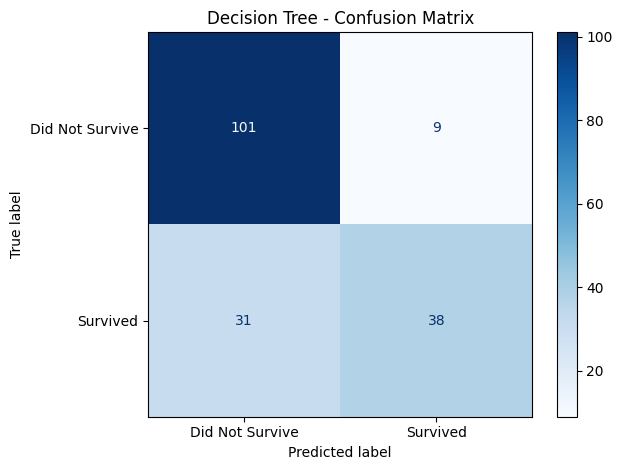

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=[
        "Did Not Survive",
        "Survived"
    ],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")

plt.tight_layout()
plt.show()

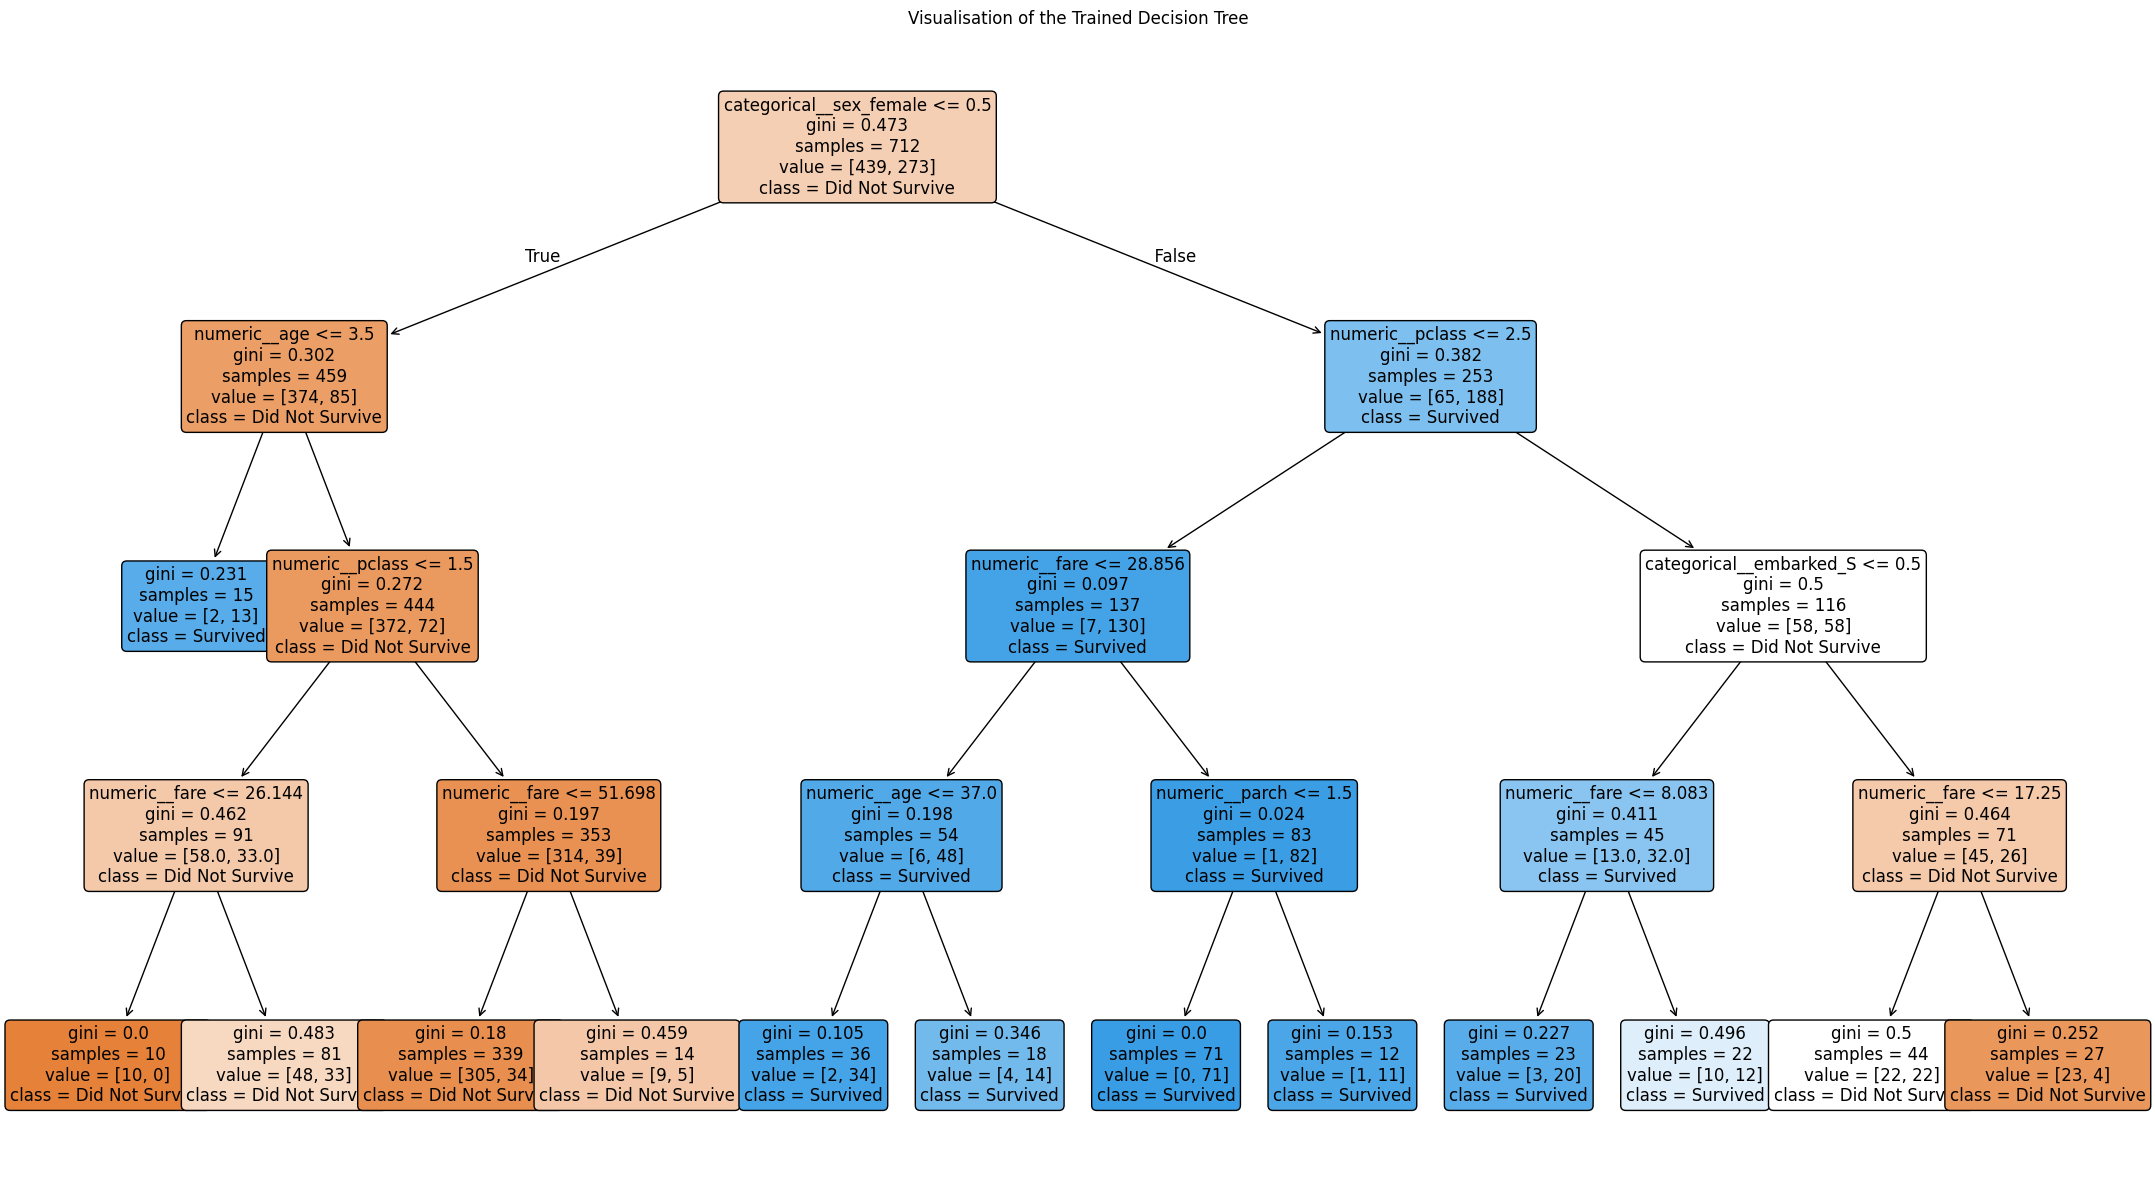

In [ ]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

plt.figure(figsize=(22, 12))

plot_tree(
    model.named_steps["classifier"],
    feature_names=feature_names,
    class_names=["Did Not Survive", "Survived"],
    filled=True,
    rounded=True,
    fontsize=12
)

plt.title("Visualisation of the Trained Decision Tree")

plt.tight_layout()
plt.show()

In [ ]:
trained_tree = model.named_steps["classifier"]

importance_values = trained_tree.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

In [ ]:
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

                   Feature  Importance
5  categorical__sex_female    0.598331
0          numeric__pclass    0.203411
1             numeric__age    0.088809
4            numeric__fare    0.069988
9  categorical__embarked_S    0.038620
3           numeric__parch    0.000840
2           numeric__sibsp    0.000000
6    categorical__sex_male    0.000000
7  categorical__embarked_C    0.000000
8  categorical__embarked_Q    0.000000


In [ ]:
top_features = importance_df.head(10).sort_values(
    by="Importance"
)

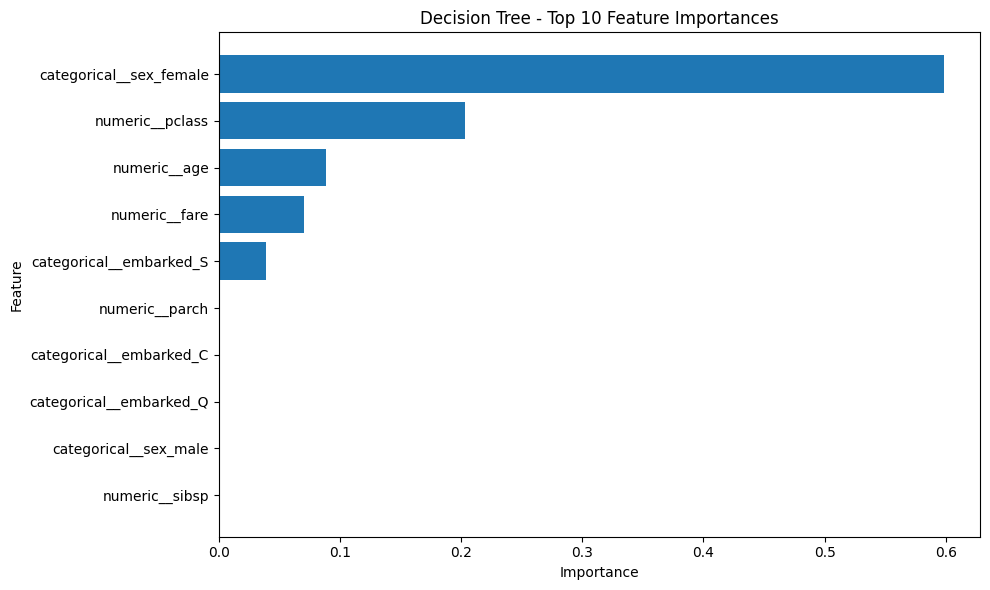

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title("Decision Tree - Top 10 Feature Importances")

plt.tight_layout()
plt.show()

In [ ]:
new_passenger = pd.DataFrame({
    "pclass": [1],
    "sex": ["female"],
    "age": [28],
    "sibsp": [0],
    "parch": [0],
    "fare": [80.0],
    "embarked": ["S"]
})

In [ ]:
prediction = model.predict(new_passenger)[0]

In [ ]:
probability = model.predict_proba(new_passenger)[0, 1]

In [ ]:
if prediction == 1:
    print("Prediction: Survived")
else:
    print("Prediction: Did not survive")

Prediction: Survived


In [ ]:
print(
    "Estimated survival probability:",
    round(probability * 100, 2),
    "%"
)

Estimated survival probability: 100.0 %
